In [22]:
import numpy as np
import pandas as pd
import seaborn as sns

In [28]:
# knn implementation from scratch - for binary classification

class knn:
    def __init__(self,k=3):
        self.k=k

    def _euclidean_dist(self,x1,x2):
        return np.sqrt(np.sum((x1-x2)**2))

    def fit(self,X,y):
        self.X_train=X
        self.y_train=y

    def _predict_one(self,x):
        distances=[self._euclidean_dist(x,x_train) for x_train in self.X_train]
        knn_indices=np.argsort(distances)[:self.k]
        knn_classes=[self.y_train[i] for i in knn_indices]
        majority_class=np.argmax(np.bincount(knn_classes))
        return majority_class

    
    def predict(self, X):
        y_pred=[self._predict_one(x) for x in X]
        return np.array(y_pred)
        

In [24]:
x_train=np.array([
    [1,2],
    [2,3],
    [3,3],
    [6,5],
    [7,7]])

y_train=np.array([0,0,0,1,1])

x_test=np.array([
    [2,2],[6,6]])

In [18]:
knn_class_temp=[0,0,1,1,0,0,2,2,3,3,5]
np.argmax(np.bincount(knn_class_temp))

np.int64(0)

   x1  x2  label
0   1   2      0
1   2   3      0
2   3   3      0
3   6   5      1
4   7   7      1


<Axes: xlabel='x1', ylabel='x2'>

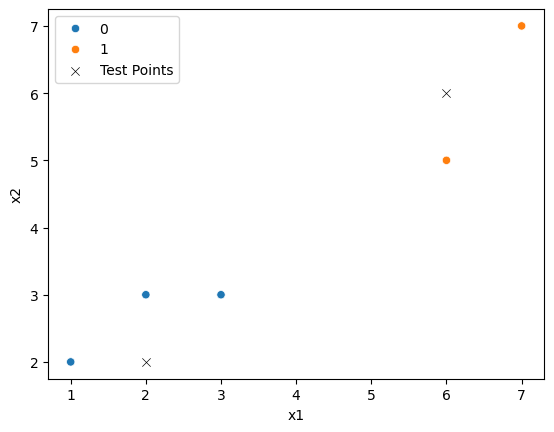

In [25]:
x_train_df=pd.DataFrame(x_train, columns=["x1","x2"])
x_train_df["label"]=y_train
sns.scatterplot(
    data=x_train_df,
    x="x1",
    y="x2",
    hue="label"
)
print(x_train_df)
x_test_df=pd.DataFrame(x_test,columns=["x1","x2"])
sns.scatterplot(data=x_test_df,
                x="x1",y="x2", color="black",
                marker="x",
                label="Test Points"
               )

In [29]:
model=knn()
model.fit(x_train, y_train)

y_pred=model.predict(x_test)
print(y_pred)

[0 1]
